In [9]:
import numpy as np
import matplotlib.pyplot as plt

## Parameters

In [10]:
D = 0.8          # diffusion coefficient, mm^2/day
n_rows = 41      # grid points across
n_cols = 41
dx = 0.2         # mm per grid point
dt = 0.005       # days per step
t_end = 4.0      # days
n_steps = int(t_end / dt)
dose = 100.0     # virus injected at the centre

snapshot_days = [0.5, 1.0, 2.0, 4.0]

## Euler's

In [11]:
limit = dx * dx / (4.0 * D)
print("dt =", dt, " limit =", limit)

dt = 0.005  limit = 0.012500000000000002


## Second Deriv.

In [12]:
def second_deriv(v, row, col):
    here = v[row, col]

    if row > 0:
        left = v[row - 1, col]
    else:
        left = here

    if row < n_rows - 1:
        right = v[row + 1, col]
    else:
        right = here

    if col > 0:
        down = v[row, col - 1]
    else:
        down = here

    if col < n_cols - 1:
        up = v[row, col + 1]
    else:
        up = here

    d2v_dx2 = (left - 2.0 * here + right) / (dx * dx)
    d2v_dy2 = (down - 2.0 * here + up) / (dx * dx)

    return d2v_dx2 + d2v_dy2

## Simulation

In [13]:
v = np.zeros((n_rows, n_cols))

centre_row = n_rows // 2
centre_col = n_cols // 2
v[centre_row, centre_col] = dose


# Run the simulation, saving a copy on the chosen days

saved = {}

for step in range(n_steps + 1):

    day = step * dt
    for want in snapshot_days:
        if want <= day < want + dt:
            saved[want] = v.copy()

    # on the very last step there is nothing left to update
    if step < n_steps:
        dv = np.zeros((n_rows, n_cols))
        for row in range(n_rows):
            for col in range(n_cols):
                dv[row, col] = D * second_deriv(v, row, col)

        v = v + dt * dv


# Check: pure diffusion only moves virus around, so the total
# should not change

for day in snapshot_days:
    print("day", day, " total =", saved[day].sum())

day 0.5  total = 100.00000000000003
day 1.0  total = 100.00000000000003
day 2.0  total = 100.00000000000006
day 4.0  total = 100.0000000000001


## Plots

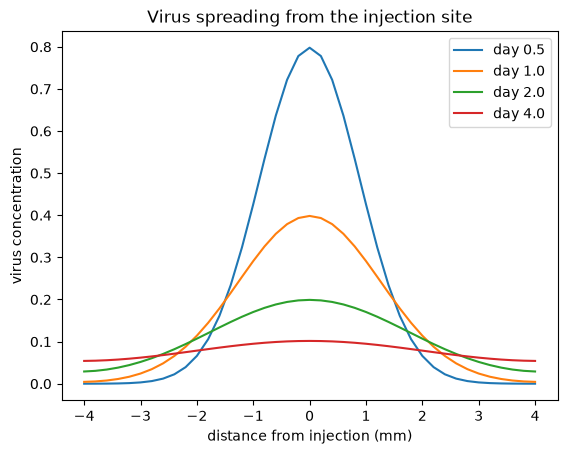

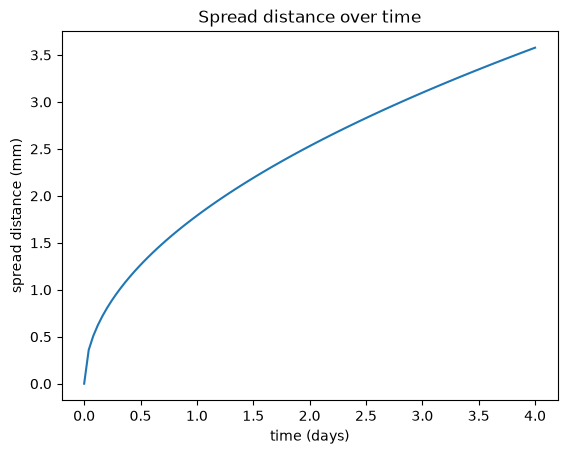

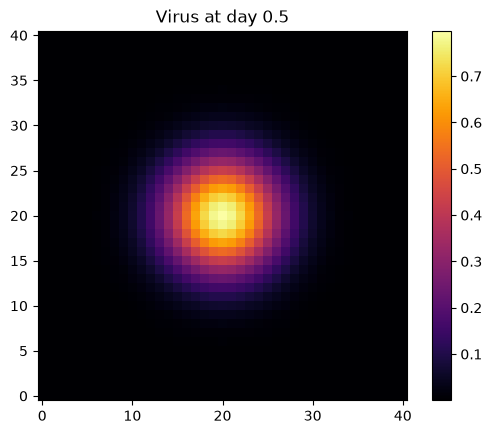

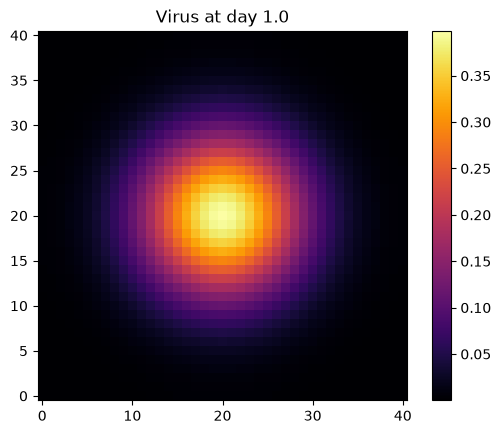

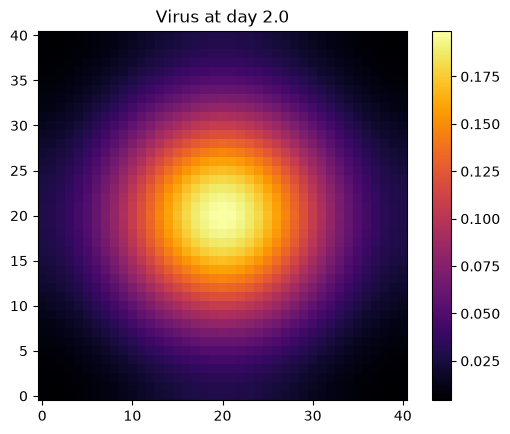

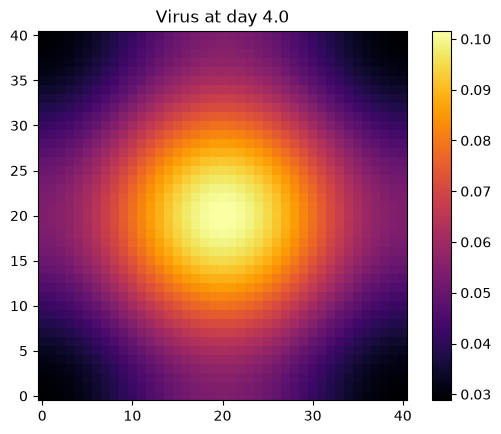

In [14]:
x = np.zeros(n_cols)
for col in range(n_cols):
    x[col] = (col - centre_col) * dx

plt.figure()
for day in snapshot_days:
    plt.plot(x, saved[day][centre_row, :], label="day " + str(day))
plt.xlabel("distance from injection (mm)")
plt.ylabel("virus concentration")
plt.title("Virus spreading from the injection site")
plt.legend()
plt.show();

# Plot 2: how far the virus has spread, compared with theory
# Theory says the spread distance grows like sqrt(4*D*t)

t = np.linspace(0.0, t_end, 100)
theory = np.sqrt(4.0 * D * t)

plt.figure()
plt.plot(t, theory)
plt.xlabel("time (days)")
plt.ylabel("spread distance (mm)")
plt.title("Spread distance over time")
plt.show();


# Plot 3: the grid itself, one picture per day

for day in snapshot_days:
    plt.figure()
    plt.imshow(saved[day], cmap="inferno", origin="lower")
    plt.colorbar()
    plt.title("Virus at day " + str(day))
    plt.show();